[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/fingerprint-similarity-guide/blob/main/notebooks/02_fingerprint_zoo.ipynb)

# 02 · The Fingerprint Zoo

*Fingerprint & Similarity Guide · Hamza Hentabli, Ph.D. · ~40 min*

There is no single "molecular fingerprint". There is a zoo of them, each encoding a different view of structure — circular environments, linear paths, atom pairs, predefined keys. Here we generate every fingerprint this course benchmarks, on the same molecules, and watch how differently they describe the *same* chemistry. The shared `fsg` module builds them all.

**Learning objectives.** By the end of this notebook you will be able to:

- generate Morgan/ECFP, FCFP, RDKit, atom-pair, torsion, MACCS and Avalon fingerprints
- compare their length, density, and what kind of structure each emphasises
- understand FCFP (feature/pharmacophore-flavoured) vs ECFP (exact atoms)
- know which optional modern fingerprints (MHFP/MAP4) exist and when to reach for them

In [1]:
# Setup: on Google Colab this installs dependencies and clones the repo so the
# cached data and the shared `fsg` helper module are available. Running locally,
# install requirements.txt once and this cell just locates the files.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("FSG_OFFLINE", "0") == "1"   # CI sets this; no notebook needs the network
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "rdkit", "scikit-learn", "scipy", "pandas", "matplotlib"], check=True)
    if not os.path.isdir("fingerprint-similarity-guide"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/fingerprint-similarity-guide.git"], check=True)
    ROOT = "fingerprint-similarity-guide"
else:
    ROOT = ".." if os.path.isdir("../data") else "."
DATA_DIR = os.path.join(ROOT, "data")
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
import fsg   # shared fingerprint factory + metrics + evaluation

print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| data:", DATA_DIR)
print("Fingerprints available:", ", ".join(fsg.FP_NAMES))

Colab: False | offline: True | data: ../data
Fingerprints available: ECFP4-1024, ECFP4-2048, ECFP6-2048, ECFP4-counts, FCFP4-2048, RDKit, AtomPair, Torsion, MACCS, Avalon


## 1. One molecule, every fingerprint

`fsg.FP_NAMES` lists the fingerprints we benchmark throughout the course. Let's build each one for erlotinib and compare how many bits each sets.

In [2]:
import pandas as pd
from rdkit import Chem
erlotinib = Chem.MolFromSmiles("C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1")

rows = []
for name in fsg.FP_NAMES:
    fp = fsg.make_fp(name, erlotinib)
    if fsg.fp_is_count(name):
        nz = fp.GetNonzeroElements()
        rows.append((name, "count", len(nz), sum(nz.values())))
    else:
        rows.append((name, "binary", fp.GetNumBits(), fp.GetNumOnBits()))
pd.DataFrame(rows, columns=["fingerprint", "type", "length", "features_set"])

,fingerprint,type,length,features_set
0,ECFP4-1024,binary,1024,47
1,ECFP4-2048,binary,2048,47
2,ECFP6-2048,binary,2048,67
3,ECFP4-counts,count,47,84
4,FCFP4-2048,binary,2048,41
5,RDKit,binary,2048,827
6,AtomPair,binary,2048,297
7,Torsion,binary,2048,50
8,MACCS,binary,167,50
9,Avalon,binary,2048,126


Already the fingerprints disagree on how much to "say" about the same molecule: MACCS has only 167 slots (predefined keys), while path- and environment-based fingerprints set hundreds of bits in a 2,048-bit space.

## 2. What each family encodes

| Family | Encodes | Flavour |
|---|---|---|
| **Morgan / ECFP** | circular atom environments (radius) | exact atom identities |
| **FCFP** | circular environments with **feature** atom types | pharmacophore-like (donor/acceptor/aromatic/…) |
| **RDKit** | linear paths through the graph | subgraph/topology |
| **Atom pairs** | (atom type, atom type, topological distance) | long-range relationships |
| **Torsions** | 4-atom linear fragments | local backbone shape |
| **MACCS** | 166 predefined substructure questions | human-readable keys |
| **Avalon** | path/feature mix from the Avalon toolkit | general-purpose |


## 3. ECFP vs FCFP — exact atoms vs pharmacophore features

ECFP distinguishes atoms by element; FCFP groups atoms by **role** (H-bond donor, acceptor, aromatic, halogen, …). So two molecules that swap one heteroatom for a similar-role atom look *more alike* to FCFP than to ECFP. We test that with a bioisostere: pyridine vs benzene.

In [3]:
benzene = Chem.MolFromSmiles("c1ccccc1")
pyridine = Chem.MolFromSmiles("c1ccncc1")
for name in ["ECFP4-2048", "FCFP4-2048"]:
    a, b = fsg.make_fp(name, benzene), fsg.make_fp(name, pyridine)
    print(f"{name:12s} Tanimoto(benzene, pyridine) = {fsg.similarity('tanimoto', a, b):.3f}")

ECFP4-2048   Tanimoto(benzene, pyridine) = 0.333
FCFP4-2048   Tanimoto(benzene, pyridine) = 0.333


FCFP sees benzene and pyridine as more similar than ECFP does, because it abstracts away the exact N-for-CH swap. That abstraction is exactly what helps **scaffold hopping** (Notebook 05).

## 4. Atom pairs capture long-range relationships

Circular fingerprints are *local*. Atom-pair fingerprints encode pairs of atoms with the topological distance between them, so they "see" that two pharmacophoric groups sit, say, 8 bonds apart — useful when the scaffold between them changes.

ECFP4-2048 gefitinib~erlotinib Tanimoto = 0.408
AtomPair   gefitinib~erlotinib Tanimoto = 0.487
RDKit      gefitinib~erlotinib Tanimoto = 0.747


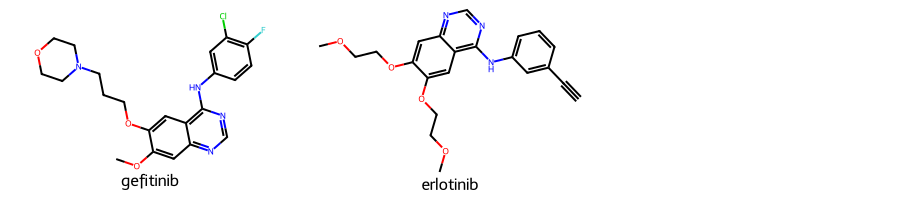

In [4]:
from rdkit.Chem import Draw
mols = [Chem.MolFromSmiles(s) for s in
        ["COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1",  # gefitinib
         "C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1"]]       # erlotinib
for name in ["ECFP4-2048", "AtomPair", "RDKit"]:
    fps = fsg.make_fps(name, mols)
    print(f"{name:10s} gefitinib~erlotinib Tanimoto = {fsg.similarity('tanimoto', fps[0], fps[1]):.3f}")
Draw.MolsToGridImage(mols, legends=["gefitinib", "erlotinib"], subImgSize=(300, 200))

Different fingerprints give **different similarity values for the same pair** — there is no single "correct" similarity, only the one that best matches your task. That is the whole point of this course.

## 5. Optional: modern hashed fingerprints (MHFP / MAP4)

`MHFP6` and `MAP4` are newer MinHash fingerprints that often do well on large, diverse libraries. They need an extra dependency (`mhfp` / `map4`) that does not always install cleanly, so they are **optional** here and are skipped automatically if unavailable.

In [5]:
try:
    from mhfp.encoder import MHFPEncoder   # pip install mhfp
    enc = MHFPEncoder(2048)
    h = enc.encode("c1ccccc1")
    print("MHFP available; vector length:", len(h))
except Exception as e:
    print("MHFP not installed (optional) — skipping. Reason:", type(e).__name__)
    print("The 7 core fingerprints above are enough for every benchmark in this course.")

MHFP not installed (optional) — skipping. Reason: ModuleNotFoundError
The 7 core fingerprints above are enough for every benchmark in this course.


## Summary

- There are **many** fingerprint families; each emphasises a different structural view.
- **ECFP** uses exact atoms; **FCFP** uses pharmacophore features and is gentler across bioisosteres.
- **Atom pairs/torsions** capture longer-range and shape information; **MACCS** uses human-readable keys.
- The *same* molecule pair gets **different** similarity depending on the fingerprint.

Next: the other half of the equation — the similarity **metric**.

### ✏️ Exercise 1

Using `fsg`, compute how many bits each binary fingerprint sets for caffeine (`CN1C=NC2=C1C(=O)N(C(=O)N2C)C`). Which is densest?

<details>
<summary><b>Show solution</b></summary>

```python
caf = Chem.MolFromSmiles("CN1C=NC2=C1C(=O)N(C(=O)N2C)C")
for n in fsg.FP_NAMES:
    if not fsg.fp_is_count(n):
        print(n, fsg.make_fp(n, caf).GetNumOnBits())
```

</details>

### ✏️ Exercise 2

Is aspirin more similar to salicylic acid under ECFP4 or under FCFP4? (aspirin `CC(=O)Oc1ccccc1C(=O)O`, salicylic acid `O=C(O)c1ccccc1O`)

<details>
<summary><b>Show solution</b></summary>

```python
a = Chem.MolFromSmiles("CC(=O)Oc1ccccc1C(=O)O")
s = Chem.MolFromSmiles("O=C(O)c1ccccc1O")
for n in ["ECFP4-2048", "FCFP4-2048"]:
    fa, fs = fsg.make_fp(n, a), fsg.make_fp(n, s)
    print(n, round(fsg.similarity("tanimoto", fa, fs), 3))
```

</details>